In [1]:
%pwd

'd:\\Tipto\\hisab-lens\\notebooks'

In [2]:
import os
os.chdir("../")

In [3]:
import json 
from pathlib import Path
from datasets import Dataset, Features, Image, Value

In [4]:
dataset_1_image_dir = Path("data/dataset_1/images")
dataset_1_annotation_dir = Path("data/dataset_1/annotations")

In [5]:
dataset_1_images = list(dataset_1_image_dir.glob("*.jpg"))
dataset_1_images

[WindowsPath('data/dataset_1/images/20210316_223932.jpg'),
 WindowsPath('data/dataset_1/images/20210318_110237.jpg'),
 WindowsPath('data/dataset_1/images/20210318_110451.jpg'),
 WindowsPath('data/dataset_1/images/20210318_110735.jpg'),
 WindowsPath('data/dataset_1/images/20210318_111439.jpg'),
 WindowsPath('data/dataset_1/images/20210318_111551.jpg'),
 WindowsPath('data/dataset_1/images/20210318_111820.jpg'),
 WindowsPath('data/dataset_1/images/20210318_113425.jpg'),
 WindowsPath('data/dataset_1/images/20210318_113703.jpg'),
 WindowsPath('data/dataset_1/images/20210318_114437.jpg'),
 WindowsPath('data/dataset_1/images/20210318_114507.jpg'),
 WindowsPath('data/dataset_1/images/20210318_115323.jpg'),
 WindowsPath('data/dataset_1/images/20210318_115839.jpg'),
 WindowsPath('data/dataset_1/images/20210318_120053.jpg'),
 WindowsPath('data/dataset_1/images/20210318_122114.jpg'),
 WindowsPath('data/dataset_1/images/20210318_122239.jpg'),
 WindowsPath('data/dataset_1/images/20210318_122424.jpg'

In [6]:
sample_annotation_path = dataset_1_images[0].parent.parent / "annotations" / f"{dataset_1_images[0].stem}.txt"
sample_annotation_path

WindowsPath('data/dataset_1/annotations/20210316_223932.txt')

In [7]:
json.loads(sample_annotation_path.read_text(encoding="utf-8").strip())

{'company': 'brisa - concessão rodoviária s.a.',
 'date': '2019-01-23',
 'address': 'quinta da torre da aguilha edificio brisa 2785-599 são domingos de rana',
 'total': '1,35',
 'invoice_number': 'FS 05021061902/0018579',
 'nif_buyer': '',
 'iva_amount': '',
 'nif_seller': '502790024'}

In [8]:
dataset_1_images = sorted(dataset_1_images, key=lambda x: x.stem)

In [9]:
annotations_dataset_1 = []
for image_path in dataset_1_images:
    # get the annotation path for the image
    annotation_path = image_path.parent.parent / "annotations" / f"{image_path.stem}.txt"
    # read the annotation file and parse the json
    annotation = json.loads(annotation_path.read_text(encoding="utf-8").strip())
    annotations_dataset_1.append(annotation)

In [10]:
len(annotations_dataset_1), len(dataset_1_images)

(813, 813)

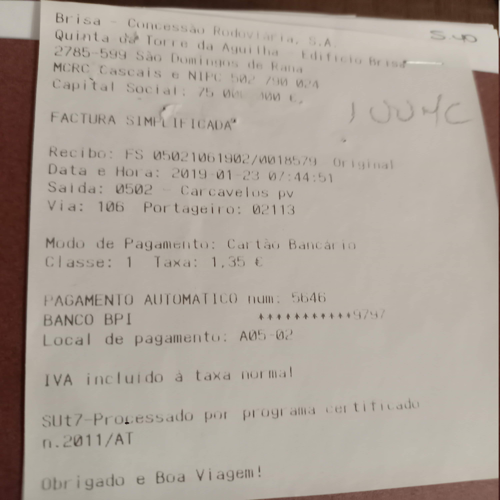

In [11]:
from transformers.image_utils import load_image

image = load_image(str(dataset_1_images[0]))
image.resize((500, 500))

In [12]:
annotations_dataset_1[0]

{'company': 'brisa - concessão rodoviária s.a.',
 'date': '2019-01-23',
 'address': 'quinta da torre da aguilha edificio brisa 2785-599 são domingos de rana',
 'total': '1,35',
 'invoice_number': 'FS 05021061902/0018579',
 'nif_buyer': '',
 'iva_amount': '',
 'nif_seller': '502790024'}

In [13]:
type(annotations_dataset_1[0]), type(dataset_1_images[0])

(dict, pathlib.WindowsPath)

In [14]:
type(json.dumps(annotations_dataset_1[0], ensure_ascii=False))

str

In [15]:
# feature schema
feature_schema = Features(
    {
        "source": Value("string"),
        "image": Image(),
        "structured_output": Value("string"),
    }
)

In [16]:
# same source name for all images in dataset_1
dataset_1_sources = ["dataset_1"] * len(dataset_1_images)
len(dataset_1_sources), len(dataset_1_images)

(813, 813)

In [17]:
dataset_1 = Dataset.from_dict(
    {
        "source": dataset_1_sources,
        "image": dataset_1_images,
        "structured_output": annotations_dataset_1,
    },
    features  =feature_schema,
)

In [18]:
dataset_1

Dataset({
    features: ['source', 'image', 'structured_output'],
    num_rows: 813
})

## now lets do the same for invoice_ocr

In [19]:
invoice_ocr_image_dir = Path("data/invoice_ocr/train/images")
invoice_ocr_images_train = list(invoice_ocr_image_dir.glob("*.jpg"))
invoice_ocr_images_train = sorted(invoice_ocr_images_train, key=lambda x: x.stem)
len(invoice_ocr_images_train)

778

In [20]:
sample = invoice_ocr_images_train[0].parent.parent / "annotations" / f"{invoice_ocr_images_train[0].stem}.json"
print(sample.read_text(encoding="utf-8").strip())

{
  "level": [
    1,
    2,
    3,
    4,
    5,
    5,
    5,
    2,
    3,
    4,
    5,
    5,
    5,
    5,
    5,
    5,
    4,
    5,
    4,
    5,
    5,
    5,
    5,
    5,
    5,
    5,
    4,
    5,
    5,
    4,
    5,
    5,
    5,
    4,
    5,
    2,
    3,
    4,
    5,
    5,
    5,
    2,
    3,
    4,
    5,
    5,
    5,
    5,
    2,
    3,
    4,
    5,
    2,
    3,
    4,
    5,
    5,
    5,
    5,
    4,
    5,
    5,
    4,
    5,
    4,
    5,
    5,
    4,
    5,
    5,
    5,
    5,
    4,
    5,
    5,
    5,
    4,
    5,
    5,
    5,
    5,
    5,
    5,
    4,
    5,
    5,
    5,
    5,
    5,
    4,
    5,
    5,
    5,
    4,
    5,
    5,
    5,
    5,
    2,
    3,
    4,
    5,
    5,
    5,
    2,
    3,
    4,
    5,
    2,
    3,
    4,
    5,
    4,
    5,
    2,
    3,
    4,
    5,
    2,
    3,
    4,
    5,
    5,
    5,
    5,
    5,
    4,
    5,
    2,
    3,
    4,
    5,
    2,
    3,
    4,
    5,
    5,
    4,
    5,
    5,
    5

In [21]:
json.loads()

TypeError: loads() missing 1 required positional argument: 's'

In [22]:
from collections import defaultdict

def ocr_dict_to_text_json(ocr_data: dict) -> dict:
    """Convert Tesseract-style word arrays into a clean line-ordered JSON object."""
    n = len(ocr_data.get("text", []))
    grouped_lines = defaultdict(list)

    for i in range(n):
        token = (ocr_data["text"][i] or "").strip()
        if not token:
            continue

        line_key = (
            ocr_data["block_num"][i],
            ocr_data["par_num"][i],
            ocr_data["line_num"][i],
        )
        grouped_lines[line_key].append(
            (
                ocr_data["word_num"][i],
                ocr_data["left"][i],
                ocr_data["top"][i],
                token,
            )
        )

    lines = []
    # Sort lines roughly by vertical position (top), then reading hierarchy
    sorted_line_items = sorted(
        grouped_lines.items(),
        key=lambda item: (
            min(w[2] for w in item[1]),
            item[0][0],
            item[0][1],
            item[0][2],
        ),
    )

    for _, words in sorted_line_items:
        words_sorted = sorted(words, key=lambda w: (w[0], w[1]))
        line_text = " ".join(w[3] for w in words_sorted).strip()
        if line_text:
            lines.append(line_text)

    return {
        "text": "\n".join(lines),
        "lines": lines,
    }


def build_formatted_dataset_2(
    image_dir: str | Path,
    annotation_dir: str | Path,
    source_name: str = "dataset_2",
) -> Dataset:
    image_dir = Path(image_dir)
    annotation_dir = Path(annotation_dir)

    image_paths = sorted(image_dir.glob("*.jpg"), key=lambda x: x.stem)

    sources = []
    images = []
    structured_outputs = []

    for img_path in image_paths:
        ann_path = annotation_dir / f"{img_path.stem}.json"
        if not ann_path.exists():
            print(f"Skipping {img_path.name}: missing {ann_path.name}")
            continue

        raw_ocr = json.loads(ann_path.read_text(encoding="utf-8").strip())
        formatted_json = ocr_dict_to_text_json(raw_ocr)

        sources.append(source_name)
        images.append(str(img_path))
        structured_outputs.append(json.dumps(formatted_json, ensure_ascii=False))

    features = Features(
        {
            "source": Value("string"),
            "image": Image(),
            "structured_output": Value("string"),
        }
    )

    return Dataset.from_dict(
        {
            "source": sources,
            "image": images,
            "structured_output": structured_outputs,
        },
        features=features,
    )

In [23]:
invoice_ocr_dataset_train = build_formatted_dataset_2(
    image_dir="data/invoice_ocr/train/images",
    annotation_dir="data/invoice_ocr/train/annotations",
    source_name="invoice_ocr",
)


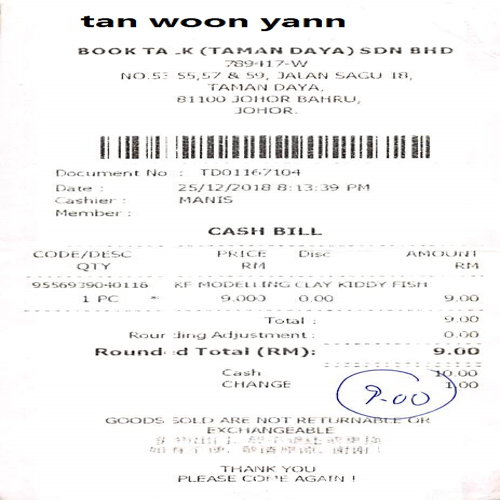

In [24]:
invoice_ocr_dataset_train[0]["image"].resize((500, 500))

In [25]:
print(json.dumps(json.loads(invoice_ocr_dataset_train[0]["structured_output"]), indent=2, ensure_ascii=False))

{
  "text": "tan woon yann\nBOOK TAK (TAMAN DAYA) SDN BHD\nB97\nNO.5? 55,57 & 59, JALAN SAGU 18,\nTAMAN DAYA\n81100 JOHOR BAHRU,\nJOHOR.\nWAM MICA A\nDocument Ho : TDO1167104\nDate 25/12/2018 8:13:39 PM\nCashier MANIS\nMember\nCASH BILL\nCODE/DESC PRICE Disc AMOUITT\nQuy RM RM\n9556939040118 KF MODELLING CLAY KIDDY FISH\n1PC * 9.00) 6,00 9.00\nTotal : 9,00\nRour ding Adjustment 0.00\n9.60\nRound::d Total (RM):\nCash\nCHANGE\nGOODS SOLD ARE NOT RETURNAR\nEXCHANGEABLE\nTHANK YOU.\nPLEASE COME AGA t",
  "lines": [
    "tan woon yann",
    "BOOK TAK (TAMAN DAYA) SDN BHD",
    "B97",
    "NO.5? 55,57 & 59, JALAN SAGU 18,",
    "TAMAN DAYA",
    "81100 JOHOR BAHRU,",
    "JOHOR.",
    "WAM MICA A",
    "Document Ho : TDO1167104",
    "Date 25/12/2018 8:13:39 PM",
    "Cashier MANIS",
    "Member",
    "CASH BILL",
    "CODE/DESC PRICE Disc AMOUITT",
    "Quy RM RM",
    "9556939040118 KF MODELLING CLAY KIDDY FISH",
    "1PC * 9.00) 6,00 9.00",
    "Total : 9,00",
    "Rour ding Adjustment 0.

In [26]:
invoice_ocr_dataset_test = build_formatted_dataset_2(
    image_dir="data/invoice_ocr/test/images",
    annotation_dir="data/invoice_ocr/test/annotations",
    source_name="invoice_ocr",
)
len(invoice_ocr_dataset_test)

98

In [27]:
invoice_ocr_dataset_val = build_formatted_dataset_2(
    image_dir="data/invoice_ocr/val/images",
    annotation_dir="data/invoice_ocr/val/annotations",
    source_name="invoice_ocr",
)
len(invoice_ocr_dataset_val)

97

In [28]:
# now the high quality invoice dataset
import pandas as pd

base_dir = Path("data/high_quality_invoice/batch_1/batch_1")

df_batch1_1 = pd.read_csv(base_dir / "batch1_1.csv")
df_batch1_2 = pd.read_csv(base_dir / "batch1_2.csv")
df_batch1_3 = pd.read_csv(base_dir / "batch1_3.csv")

In [29]:
df_batch1_1.iloc[0]

File Name                                       batch1-0494.jpg
Json Data     \n{\n  "invoice": {\n    "client_name": "Clark...
OCRed Text    Invoice no: 84652373 Date of issue: 02/23/2021...
Name: 0, dtype: str

In [30]:
def build_batch_dataset(
    df: pd.DataFrame,
    image_dir: str | Path,
    source_name: str,
) -> Dataset:
    image_dir = Path(image_dir)

    # Index available images by filename (and stem fallback) for fast lookup
    by_name = {p.name: p for p in image_dir.glob("*.jpg")}
    by_stem = {p.stem: p for p in image_dir.glob("*.jpg")}

    sources = []
    images = []
    structured_outputs = []
    missing = 0

    for _, row in df.iterrows():
        raw_name = str(row["File Name"]).strip()
        img_path = by_name.get(raw_name) or by_stem.get(Path(raw_name).stem)

        if img_path is None or not img_path.exists():
            missing += 1
            continue

        raw_json = str(row["Json Data"]).strip()
        parsed_json = json.loads(raw_json)

        sources.append(source_name)
        images.append(str(img_path))
        structured_outputs.append(json.dumps(parsed_json, ensure_ascii=False))

    if missing:
        print(f"[{source_name}] Skipped {missing} rows with missing images.")

    features = Features(
        {
            "source": Value("string"),
            "image": Image(),
            "structured_output": Value("string"),
        }
    )

    return Dataset.from_dict(
        {
            "source": sources,
            "image": images,
            "structured_output": structured_outputs,
        },
        features=features,
    )

In [31]:
ds_1 = build_batch_dataset(df_batch1_1, base_dir / "batch1_1", "batch1_1")
ds_2 = build_batch_dataset(df_batch1_2, base_dir / "batch1_2", "batch1_2")
ds_3 = build_batch_dataset(df_batch1_3, base_dir / "batch1_3", "batch1_3")

In [32]:
from datasets import concatenate_datasets
combined_dataset = concatenate_datasets([ds_1, ds_2, ds_3])

In [33]:
combined_dataset[0]

{'source': 'batch1_1',
 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1654x2339>,
 'structured_output': '{"invoice": {"client_name": "Clark-Foster", "client_address": "77477 Troy Cliff Apt. 853\\nWashingtonbury, MS 78346", "seller_name": "Nguyen-Roach", "seller_address": "247 David Highway\\nLake John, WV 84178", "invoice_number": "84652373", "invoice_date": "02/23/2021", "due_date": ""}, "items": [{"description": "Stemware Rack Display Kitchen\\nWine Glass Holder Bottle\\nCarbon Steel Free Punch", "quantity": "1.00", "total_price": "46.55"}, {"description": "VTG (4) 7 Ounce Since 1852\\nMilk Bottle Wine Carafe Juice\\nGlass with Cork Lids", "quantity": "1.00", "total_price": "15.40"}, {"description": "Vintage Crystal Red Wine\\nGlasses NOS West Germany\\n1983 6 10 ounce elegant stems", "quantity": "1.00", "total_price": "39.00"}, {"description": "3 Ikea Stainless Steel 4-bottle\\nWine Rack 300.557.60 - great\\ncondition gift it!", "quantity": "4.00", "total_price": "

In [34]:
final_ocr_dataset = concatenate_datasets([dataset_1, invoice_ocr_dataset_train, invoice_ocr_dataset_test, invoice_ocr_dataset_val, combined_dataset])
final_ocr_dataset

Dataset({
    features: ['source', 'image', 'structured_output'],
    num_rows: 3200
})

In [35]:
final_ocr_dataset = final_ocr_dataset.shuffle(seed=42)

In [36]:
from datasets import DatasetDict
SEED = 42

# split 70% train, 15% validation, 15% test
train_split = final_ocr_dataset.train_test_split(test_size=0.3, seed=SEED)

# split the 30% equally into validation and test sets
temp_splits = train_split["test"].train_test_split(test_size=0.5, seed=SEED)

# assemble the final DatasetDict
final_dataset_dict = DatasetDict(
    {
        "train": train_split["train"],
        "validation": temp_splits["test"],
        "test": temp_splits["train"],
    }
)
final_dataset_dict

DatasetDict({
    train: Dataset({
        features: ['source', 'image', 'structured_output'],
        num_rows: 2240
    })
    validation: Dataset({
        features: ['source', 'image', 'structured_output'],
        num_rows: 480
    })
    test: Dataset({
        features: ['source', 'image', 'structured_output'],
        num_rows: 480
    })
})

In [37]:
# save on disk
output_dir = Path("data/final_ocr_dataset")
final_dataset_dict.save_to_disk(output_dir)

Saving the dataset (0/2 shards):   0%|          | 0/2240 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/480 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/480 [00:00<?, ? examples/s]